# Arquitectura del Pipeline de Modelado

### Setup y Carga desde BigQuery

In [21]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery

# Modelado y preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# Cargar variables de entorno
load_dotenv('../.env')
credentials_path = os.getenv('GOOGLE_APPLICATION_CREDENTIALS')
if credentials_path and not os.path.isabs(credentials_path):
    os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = os.path.abspath(
        os.path.join('..', credentials_path)
    )

PROJECT_ID = os.getenv('GCP_PROJECT_ID')
DATASET_ID = os.getenv('GCP_DATASET_ID')
TABLE_NAME = 'telco_churn_features'

client = bigquery.Client(project=PROJECT_ID)
query = f'SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}`'
df = client.query(query).to_dataframe()

print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas.')

Dataset cargado: 7043 filas x 33 columnas.


### Separación de Features, Target y Split

In [22]:
# se excluyen columnas que no se van a utilizar

drop_cols = [
    'customer_id',  
    'country',  
    'state',  
    'city',  
    'zip_code',  
    'latitude',  
    'longitude',
    'cltv',  
    'monthly_to_avg_charge_ratio',  
    'churn_target'
]

X = df.drop(columns=drop_cols)
y = df['churn_target']

# Se identifican las columnas numericas
columnas_numericas = X.select_dtypes(include=[np.number]).columns.tolist()
columnas_categoricas = X.select_dtypes(exclude=[np.number]).columns.tolist()

print(f'Varibles predictoras totales: {X.shape[1]}')

print(f'    - Numericas: ({len(columnas_numericas)}): {columnas_numericas}')
print(f'    - Categoricas: ({len(columnas_categoricas)}): {columnas_categoricas}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.20, stratify=y, random_state=42
)

print(
    f'\nConjunto de entrenamiento: {X_train.shape[0]:,} registros (Churn {y_train.mean():.2%})'
)

print(
    f'\nConjunto de prueba: {X_test.shape[0]:,} registros (Churn: {y_test.mean():.2%})'
)


Varibles predictoras totales: 23
    - Numericas: (7): ['senior_citizen', 'tenure_months', 'monthly_charges', 'total_charges', 'total_vas_services', 'is_month_to_month', 'high_risk_fiber_no_support']
    - Categoricas: (16): ['gender', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'tenure_cohort']

Conjunto de entrenamiento: 5,634 registros (Churn 26.54%)

Conjunto de prueba: 1,409 registros (Churn: 26.54%)


### Partición Estratificada y Aislamiento de Variables

* **Variables Predictoras (23 features):** Se aislaron 7 numéricas y 16 categóricas.
* **Exclusiones Preventivas:**
  * Se removieron identificadores unívocos (`customer_id`) y geografía de alta dispersión (`city`, `zip_code`, `lat/long`) para evitar memorización espuria (patrones irrelevantes).
  * Se excluyó `cltv` para reservarlo como variable de evaluación del valor económico en riesgo y no sesgar la detección conductual de churn.
  * Se retiró `monthly_to_avg_charge_ratio` tras comprobarse su nulo poder predictivo en el EDA.
* **Split Estratificado (80/20):**
  * Al haber un 26.54% de clase positiva, el parámetro `stratify=y` garantiza que tanto el conjunto de entrenamiento (5,634 filas) como el de validación (1,409 filas) mantengan exactamente la misma tasa de fuga, evitando sesgos de partición.

### Pipeline de Preprocesamiento

In [23]:

tranformador_numerico = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

tranformador_categorico = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Not Specified')),

        ('onehot',OneHotEncoder(
            handle_unknown='ignore', drop='first', sparse_output=False
        )
    )
]
)

preprocesador = ColumnTransformer(
    transformers=[
        ('num', tranformador_numerico, columnas_numericas),
        ('cat', tranformador_categorico, columnas_categoricas)
    ],
    remainder='drop'
)

### Entrenamiento y Benchmark de Modelos

In [24]:
ratio_imbalance = (len(y_train) - sum(y_train)) / sum(y_train)

modelos = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    )
    ,'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    )
    ,'XGBoost': XGBClassifier(
        scale_pos_weight=ratio_imbalance,
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    )
}

resultados = []
pipelines_ajustados = {}

for nombre,modelo in modelos.items():
    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocesador),
            ('classifier', modelo)
        ]
    )

    pipeline.fit(X_train, y_train)
    pipelines_ajustados[nombre] = pipeline

    # Predicciones
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Metricas
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    f1 = f1_score(y_test, y_pred)

    resultados.append(
        {
            'Modelo': nombre,
            'ROC-AUC': round(roc_auc,4),
            'PR-AUC': round(pr_auc,4),
            'F1-Score': round(f1, 4)
        }
    )

df_resultados = pd.DataFrame(resultados).sort_values(by='PR-AUC', ascending=False)
display(df_resultados)


,Modelo,ROC-AUC,PR-AUC,F1-Score
0,Logistic Regression,0.8362,0.6653,0.6105
2,XGBoost,0.8214,0.6069,0.5988
1,Random Forest,0.8265,0.6067,0.5887


### Diagnóstico del Benchmark Inicial

1. **Rendimiento Sorprendente de la Regresión Logística:**
   * **Logistic Regression lidera el benchmark** con un **ROC-AUC de 0.8362**, **PR-AUC de 0.6653** y **F1-Score de 0.6105**, superando a los modelos basados en árboles (`Random Forest` y `XGBoost` con PR-AUC de ~0.606). ësto se podría explicar ya que en problemas tabulares de comportamiento y servicios con variables binarias y numéricas bien escaladas, las relaciones log-lineales directas suelen ser muy estables. Adicionalmente, `class_weight='balanced'` ajusta la frontera de decisión lineal de forma muy eficiente sin caer en sobreajuste (*overfitting*).

2. **Árboles y Ensambles en su configuración por defecto:**
   * `Random Forest` y `XGBoost` operaron con hiperparámetros estándar (sin calibración de profundidad, tasa de aprendizaje ni regularización). Al no estar optimizados, los árboles tienden a fragmentar demasiado el espacio de características con variables dummy dispersas, afectando la precisión en la clase minoritaria.

3. **Métrica Clave (PR-AUC vs ROC-AUC):**
   * Mientras que el ROC-AUC es similar entre los tres modelos (~0.82 - 0.83), la diferencia crítica está en el **PR-AUC (0.665 vs 0.606)**. En datasets con desbalance (26% de positivos), el PR-AUC penaliza drásticamente los falsos positivos y refleja con mayor fidelidad la calidad de la priorización comercial.

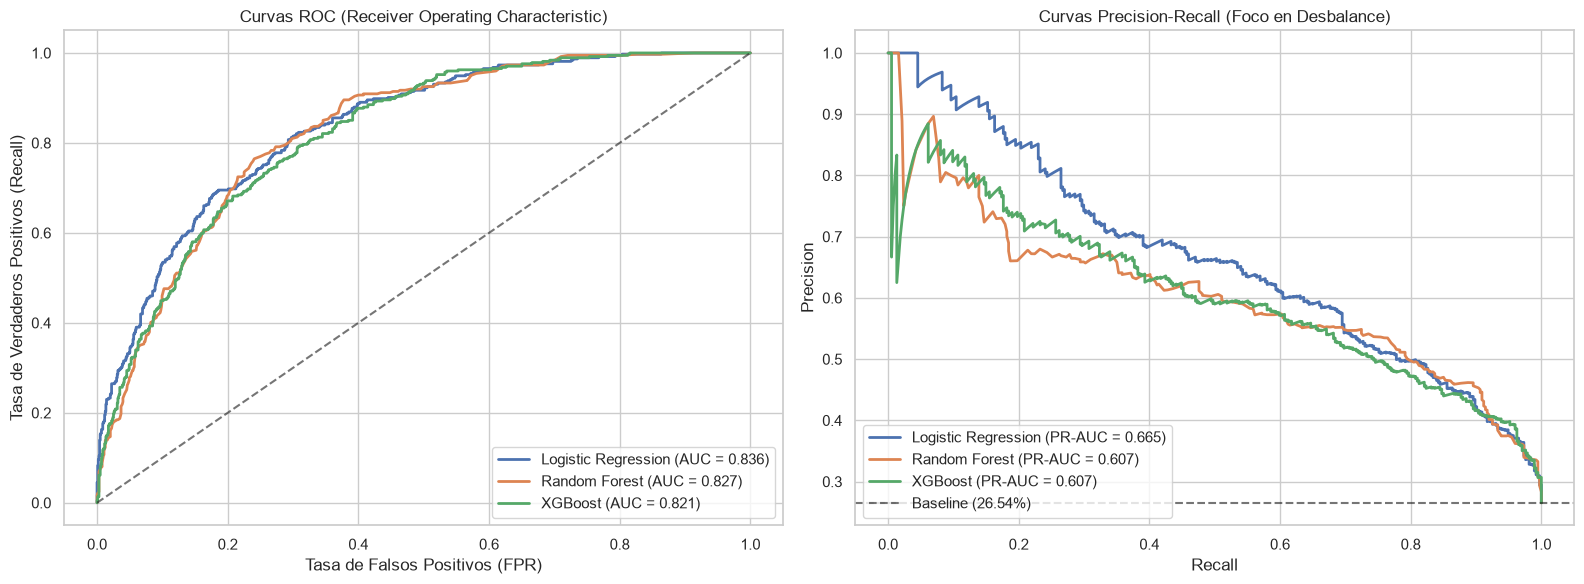

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, pipeline in pipelines_ajustados.items():
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # 1. Curva ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})",
        lw=2,
    )

    # 2. Curva Precision-Recall
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(
        rec,
        prec,
        label=f"{name} (PR-AUC = {average_precision_score(y_test, y_proba):.3f})",
        lw=2,
    )

# Estilos Curva ROC
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6)
axes[0].set_title("Curvas ROC (Receiver Operating Characteristic)")
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (Recall)")
axes[0].legend(loc="lower right")

# Estilos Curva Precision-Recall
axes[1].axhline(y=y_test.mean(), color="k", linestyle="--", alpha=0.6, label=f"Baseline ({y_test.mean():.2%})")
axes[1].set_title("Curvas Precision-Recall (Foco en Desbalance)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### Análisis de Curvas y Viabilidad Operativa

* **Curva ROC:**
  * Los tres modelos superan con amplitud la diagonal aleatoria (AUC > 0.82), confirmando que el conjunto de variables seleccionadas posee alta capacidad de separación entre clientes que desertan y clientes que permanecen.

* **Curva Precision-Recall:**
  * La línea segmentada horizontal marca el **baseline del 26.54%** (tasa de acierto al azar).
  * La curva de `Logistic Regression` domina consistentemente sobre las demás en el tramo de **Recall entre 0.10 y 0.50**, alcanzando precisiones por encima del **80% - 90%**.
  ¿Cómo este modelo puede impactar al negocio?, por ejemplo si el equipo de retención cuenta con un presupuesto acotado para intervenir al 20% de los clientes más críticos, la Regresión Logística asegura que al menos 8 de cada 10 clientes contactados realmente estaban a punto de fugarse, minimizando el desperdicio de subsidios o descuentos en clientes que se habrían quedado igual.

* **Conclusión:**
  * La Regresión Logística queda establecida como el **modelo baseline de referencia**.
  * El siguiente paso técnico es someter a **XGBoost a una optimización bayesiana de hiperparámetros con Optuna** para verificar si, con una arquitectura ajustada (`max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `gamma`), logra superar la barrera del 0.665 de PR-AUC.